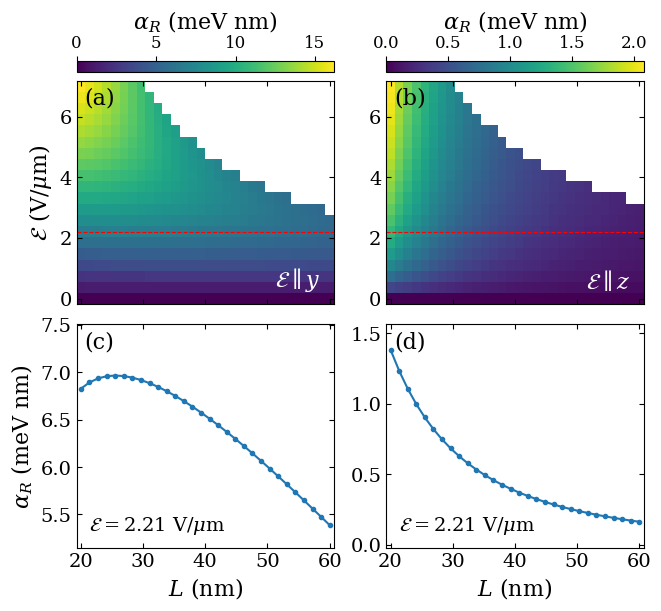

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
})

filenames = [
    "Pymablock_Y_kx0.001_valid_regions_N100.dat",
    "Pymablock_Z_kx0.001_valid_regions_N100.dat",
]

titles = [
    r"$\mathcal{E}\parallel y$",
    r"$\mathcal{E}\parallel z$",
]

field_index = 6  # 7th electric-field value

fig, axes = plt.subplots(
    2, 2,
    figsize=(6.5, 6),
    sharex="col",
    constrained_layout=True,
)

for col, (filename, title) in enumerate(zip(filenames, titles)):
    ax_map = axes[0, col]
    ax_line = axes[1, col]

    data = np.loadtxt(filename)

    L_values, L_index = np.unique(data[:, 0], return_inverse=True)
    E_values, E_index = np.unique(data[:, 1], return_inverse=True)

    # Rows: E; columns: L. Points outside the valid region stay NaN (blank).
    alpha_grid = np.full((len(E_values), len(L_values)), np.nan)
    alpha_grid[E_index, L_index] = data[:, 2] * 100  # eV Å → meV nm

    E_actual = E_values[field_index]

    # Top row: color maps
    pcm = ax_map.pcolormesh(L_values, E_values, alpha_grid, shading="auto", cmap="viridis")
    ax_map.axhline(E_actual, linestyle="--", color="red", linewidth=0.8)

    ax_map.text(
        0.95, 0.05, title,
        transform=ax_map.transAxes,
        fontsize=16,
        color="white",
        ha="right",
        va="bottom",
    )

    cbar = fig.colorbar(pcm, ax=ax_map, location="top", pad=0.04, fraction=0.08, aspect=25)
    cbar.set_label(r"$\alpha_R$ (meV nm)", fontsize=16)
    cbar.ax.tick_params(labelsize=12)

    # Bottom row: alpha_R versus L at the selected field (NaN = invalid, not drawn)
    ax_line.plot(
        L_values,
        alpha_grid[field_index, :],
        "-o",
        color="tab:blue",
        linewidth=1.5,
        markersize=3,
    )
    ax_line.text(
        0.05, 0.15,
        rf"$\mathcal{{E}}={E_actual:.2f}$ V/$\mu$m",
        transform=ax_line.transAxes,
        fontsize=14,
        ha="left",
        va="top",
    )
    ax_line.set_xlabel(r"$L$ (nm)", fontsize=16)
    ax_line.margins(y=0.15)

    for ax in (ax_map, ax_line):
        ax.tick_params(labelsize=14, direction="in", top=True, right=True)

axes[0, 0].set_ylabel(r"$\mathcal{E}$ (V/$\mu$m)", fontsize=16)
axes[1, 0].set_ylabel(r"$\alpha_R$ (meV nm)", fontsize=16)

# Panel (c): extra headroom so the label does not overlap the data
lo, hi = axes[1, 0].get_ylim()
axes[1, 0].set_ylim(lo, hi + 0.15 * (hi - lo))

for ax, label in zip(axes.flat, ["(a)", "(b)", "(c)", "(d)"]):
    ax.text(
        0.03, 0.97, label,
        transform=ax.transAxes,
        fontsize=16,
        ha="left",
        va="top",
    )

for ax in axes[0, :]:
    ax.tick_params(axis="x", labelbottom=False)

for ax in axes[1, :]:
    ax.set_xticks([20, 30, 40, 50, 60])

fig.savefig("Fig-7.pdf", dpi=300, bbox_inches="tight")
fig.savefig("Fig-7.svg", dpi=300, bbox_inches="tight")
plt.show()


## Calculate spin orbit length

$\mathcal{E}\parallel y$: min l_so = 59.16 nm at E = 7.0000 V/um, L = 20.000 nm (alpha_R = 16.192 meV nm)
$\mathcal{E}\parallel z$: min l_so = 461.15 nm at E = 7.0000 V/um, L = 20.000 nm (alpha_R = 2.077 meV nm)


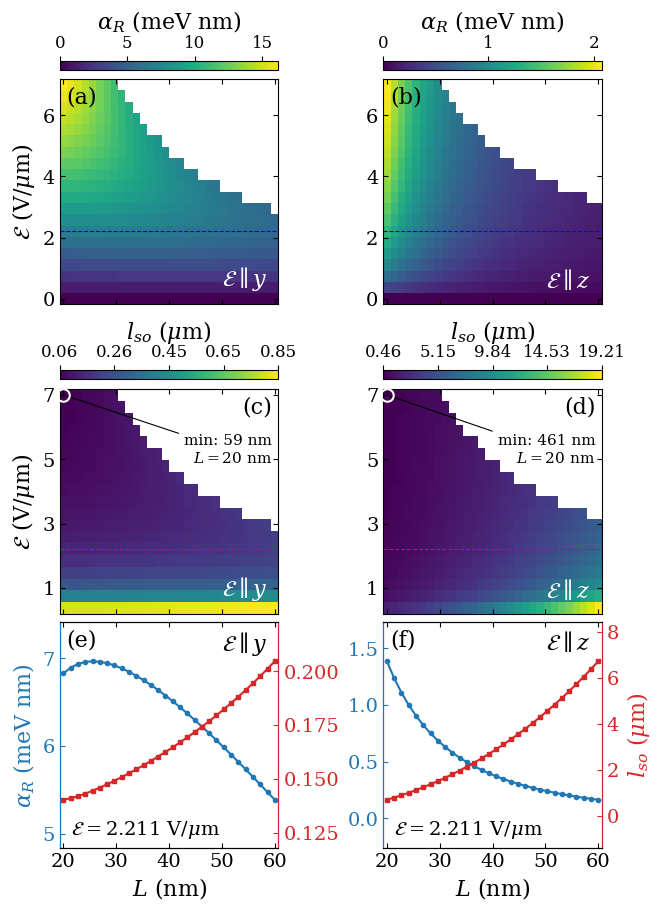

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: L (nm), effective mass (units of the free-electron mass m0), one row per cross-section
effective_mass = np.load("eff_data.npy")

HBAR2_OVER_M0 = 7.61996  # hbar^2 / m0 in eV Å^2

ALPHA_COLOR = "tab:blue"
LSO_COLOR = "tab:red"

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
})

filenames = [
    "Pymablock_Y_kx0.001_valid_regions_N100.dat",
    "Pymablock_Z_kx0.001_valid_regions_N100.dat",
]

titles = [
    r"$\mathcal{E}\parallel y$",
    r"$\mathcal{E}\parallel z$",
]

field_index = 6  # 7th electric-field value

fig, axes = plt.subplots(
    3, 2,
    figsize=(6.5, 9),
    sharex="col",
    constrained_layout=True,
)

twin_axes = []

for col, (filename, title) in enumerate(zip(filenames, titles)):
    ax_map = axes[0, col]
    ax_lso = axes[1, col]
    ax_line = axes[2, col]

    data = np.loadtxt(filename)

    L_values, L_index = np.unique(data[:, 0], return_inverse=True)
    E_values, E_index = np.unique(data[:, 1], return_inverse=True)

    # Rows: E; columns: L. Points outside the valid region stay NaN (blank).
    alpha_ev_A = np.full((len(E_values), len(L_values)), np.nan)
    alpha_ev_A[E_index, L_index] = data[:, 2]  # eV Å
    alpha_grid = alpha_ev_A * 100  # eV Å → meV nm

    # Spin-orbit length l_so = hbar^2 / (m* |alpha_R|), with m* matched to each L
    m_of_L = np.abs(np.interp(L_values, effective_mass[:, 0], effective_mass[:, 1]))
    with np.errstate(divide="ignore", invalid="ignore"):
        l_so_grid = HBAR2_OVER_M0 / (m_of_L[None, :] * np.abs(alpha_ev_A)) / 1e4  # Å → μm
    l_so_grid[~np.isfinite(l_so_grid)] = np.nan  # alpha_R = 0 → undefined

    E_actual = E_values[field_index]

    # Minimum spin-orbit length and where it occurs
    i_E, i_L = np.unravel_index(np.nanargmin(l_so_grid), l_so_grid.shape)
    print(f"{title}: min l_so = {l_so_grid[i_E, i_L] * 1e3:.2f} nm at "
          f"E = {E_values[i_E]:.4f} V/um, L = {L_values[i_L]:.3f} nm "
          f"(alpha_R = {alpha_grid[i_E, i_L]:.3f} meV nm)")

    # Top row: alpha_R color maps
    pcm = ax_map.pcolormesh(L_values, E_values, alpha_grid, shading="auto", cmap="viridis")
    ax_map.axhline(E_actual, linestyle="--", color="blue", linewidth=0.8)

    ax_map.text(
        0.95, 0.05, title,
        transform=ax_map.transAxes,
        fontsize=16,
        color="white",
        ha="right",
        va="bottom",
    )

    cbar = fig.colorbar(pcm, ax=ax_map, location="top", pad=0.04, fraction=0.08, aspect=25)
    cbar.set_label(r"$\alpha_R$ (meV nm)", fontsize=16)
    cbar.ax.tick_params(labelsize=12)

    # Middle row: spin-orbit length color maps, starting from the first finite field
    # (at E = 0, alpha_R = 0, so l_so -> infinity and is left out)
    E_lso = E_values[1:]
    l_so_plot = l_so_grid[1:, :]

    pcm_lso = ax_lso.pcolormesh(
        L_values, E_lso, l_so_plot,
        shading="auto", cmap="viridis",
    )
    ax_lso.axhline(E_actual, linestyle="--", color="red", linewidth=0.8)

    ax_lso.text(
        0.95, 0.05, title,
        transform=ax_lso.transAxes,
        fontsize=16,
        color="white",
        ha="right",
        va="bottom",
    )

    # Mark the minimum l_so with an open white circle
    l_min = l_so_grid[i_E, i_L]
    ax_lso.plot(L_values[i_L], E_values[i_E], marker="o", markersize=9,
                markerfacecolor="none", markeredgecolor="white", markeredgewidth=1.5,
                linestyle="none", zorder=5)
    ax_lso.annotate(
        rf"min: {l_min * 1e3:.0f} nm" + "\n" + rf"$L={L_values[i_L]:.0f}$ nm",
        xy=(L_values[i_L], E_values[i_E]), xytext=(0.97, 0.80), textcoords="axes fraction",
        fontsize=11, color="black", ha="right", va="top",
        arrowprops=dict(arrowstyle="-", color="black", lw=0.8),
    )

    dE = E_lso[1] - E_lso[0]
    ax_lso.set_ylim(E_lso[0] - dE / 2, E_lso[-1] + dE / 2)  # edges of the plotted cells
    ax_lso.set_yticks([1, 3, 5, 7])

    cbar_lso = fig.colorbar(pcm_lso, ax=ax_lso, location="top", pad=0.04, fraction=0.08, aspect=25)
    cbar_lso.set_label(r"$l_{so}$ ($\mu$m)", fontsize=16)
    cbar_lso.ax.tick_params(labelsize=12)
    # Colorbar ticks start at the minimum l_so
    cbar_lso.set_ticks(np.linspace(l_min, np.nanmax(l_so_plot), 5))
    cbar_lso.ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))

    # Bottom row: alpha_R (left axis) and l_so (right axis) versus L at the selected field
    ax_line.plot(
        L_values,
        alpha_grid[field_index, :],
        "-o",
        color=ALPHA_COLOR,
        linewidth=1.5,
        markersize=3,
    )
    ax_line.text(
        0.05, 0.03,
        rf"$\mathcal{{E}}={E_actual:.3f}$ V/$\mu$m",
        transform=ax_line.transAxes,
        fontsize=14,
        ha="left",
        va="bottom",
    )
    ax_line.text(
        0.95, 0.97, title,
        transform=ax_line.transAxes,
        fontsize=16,
        ha="right",
        va="top",
    )
    ax_line.set_xlabel(r"$L$ (nm)", fontsize=16)
    ax_line.margins(y=0.15)

    ax_twin = ax_line.twinx()
    ax_twin.plot(
        L_values,
        l_so_grid[field_index, :],
        "-s",
        color=LSO_COLOR,
        linewidth=1.5,
        markersize=3,
    )
    ax_twin.margins(y=0.15)
    ax_twin.tick_params(axis="y", labelsize=14, direction="in", colors=LSO_COLOR)
    ax_twin.spines["right"].set_color(LSO_COLOR)
    ax_twin.spines["left"].set_color(ALPHA_COLOR)
    twin_axes.append(ax_twin)

    for ax in (ax_map, ax_lso):
        ax.tick_params(labelsize=14, direction="in", top=True, right=True)
    # Bottom row: right side belongs to the l_so axis, left side colored for alpha_R
    ax_line.tick_params(labelsize=14, direction="in", top=True, right=False)
    ax_line.tick_params(axis="y", colors=ALPHA_COLOR)

axes[0, 0].set_ylabel(r"$\mathcal{E}$ (V/$\mu$m)", fontsize=16)
axes[1, 0].set_ylabel(r"$\mathcal{E}$ (V/$\mu$m)", fontsize=16)
axes[2, 0].set_ylabel(r"$\alpha_R$ (meV nm)", fontsize=16, color=ALPHA_COLOR)
twin_axes[1].set_ylabel(r"$l_{so}$ ($\mu$m)", fontsize=16, color=LSO_COLOR)

# Bottom row: room at the bottom for the field label and at the top for the panel label
for ax in (axes[2, 0], twin_axes[0], axes[2, 1], twin_axes[1]):
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - 0.15 * (hi - lo), hi + 0.10 * (hi - lo))

for i, (ax, label) in enumerate(zip(axes.flat, ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"])):
    right = i in (2, 3)  # (c), (d): top-left holds the minimum marker, so label goes top-right
    ax.text(
        0.97 if right else 0.03, 0.97, label,
        transform=ax.transAxes,
        fontsize=16,
        color="black",
        ha="right" if right else "left",
        va="top",
    )

for ax in axes[:2, :].flat:
    ax.tick_params(axis="x", labelbottom=False)

for ax in axes[2, :]:
    ax.set_xticks([20, 30, 40, 50, 60])

fig.savefig("Fig-7-new.pdf", dpi=300, bbox_inches="tight")
fig.savefig("Fig-7-new.svg", dpi=300, bbox_inches="tight")
plt.show()